## 1. Settings

In [1]:
# The rule is strictly below 30% to reproduce the PDF country sample.
# Total is missing only when neither Life nor Non-life has an available amount.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from IPython.display import display

# Locate the repository from the current folder (repository root or code/).
working_folder = Path.cwd().resolve()
project_folder = next(
    (folder for folder in (working_folder, *working_folder.parents)
     if all((folder / name).is_dir() for name in ("code", "dataset_raw", "dataset_analysis"))),
    None,
)
if project_folder is None:
    raise FileNotFoundError(
        "Open Jupyter from the repository root or its code folder. "
        "Expected code/, dataset_raw/, and dataset_analysis/."
    )
insurance_file = project_folder / "dataset_analysis" / "01_scoped_insurance_history.csv"
data_folder = project_folder / "dataset_analysis"
save_figures = False


if not insurance_file.exists():
    raise FileNotFoundError("Run 01_data_overview.ipynb first.")

analysis_years = list(range(1995, 2025))
year_columns = [str(year) for year in analysis_years]

maximum_missing_percent = 30  # Strictly below this percentage for the final exports.

insurance_type_to_sector = {
    "Life": "Life", "Composite: life": "Life",
    "Non-life": "Non-life", "Composite: non-life": "Non-life",
}

insurance_sectors = ["Life", "Non-life", "Total"]

business_types = ["Direct business", "Reinsurance accepted", "Total"]

data_folder.mkdir(parents=True, exist_ok=True)

## 2. Load the scoped rows and keep 1995-2024

In [2]:

country_names_by_code = pd.read_csv(
    data_folder / "01_country_labels.csv", dtype=str, keep_default_na=False
).set_index("REF_AREA")["Country"]

scoped_history = pd.read_csv(insurance_file, dtype=str, keep_default_na=False)
filtered_insurance_rows = scoped_history.loc[scoped_history["TIME_PERIOD"].isin(year_columns)].copy()
filtered_insurance_rows = filtered_insurance_rows.loc[filtered_insurance_rows["REF_AREA"].isin(country_names_by_code.index)].copy()

# Keep the original columns and values unchanged for the CSV export.
original_insurance_columns = filtered_insurance_rows.columns.tolist()
filtered_insurance_rows["Year"] = filtered_insurance_rows["TIME_PERIOD"].astype(int)

# Strip spreadsheet text formatting, but never convert missing values to zero.
values = filtered_insurance_rows["OBS_VALUE"].str.strip().str.lstrip("'")
values = values.mask(values.eq(""))

filtered_insurance_rows["premium_usd_millions"] = pd.to_numeric(values, errors="raise")
filtered_insurance_rows["premium_usd_millions"] *= 10.0 ** (pd.to_numeric(filtered_insurance_rows["UNIT_MULT"], errors="raise") - 6)

country_year_type_keys = ["REF_AREA", "Year", "Insurance type"]

if filtered_insurance_rows.duplicated(country_year_type_keys + ["Insurance business"]).any():
    raise ValueError("Duplicate series remain. Review the dimensional filters before summing.")

del scoped_history

print(f"Loaded {len(filtered_insurance_rows):,} filtered rows; {len(country_names_by_code)} countries/areas; {len(analysis_years)} years.")

Loaded 13,632 filtered rows; 71 countries/areas; 30 years.


## 3. Choose components or the reported Total fallback

In [3]:
all_country_year_type_combinations = pd.MultiIndex.from_product(
    [country_names_by_code.index, analysis_years, list(insurance_type_to_sector)], names=country_year_type_keys
)

premiums_by_business_type = filtered_insurance_rows.pivot(
    index=country_year_type_keys, columns="Insurance business", values="premium_usd_millions"
).reindex(index=all_country_year_type_combinations, columns=business_types)

direct_business_premiums = premiums_by_business_type["Direct business"]
reinsurance_accepted_premiums = premiums_by_business_type["Reinsurance accepted"]
direct_plus_reinsurance_premiums = premiums_by_business_type[business_types[:2]].sum(axis=1, min_count=1)
use_reported_total_fallback = direct_plus_reinsurance_premiums.isna() & premiums_by_business_type["Total"].notna()

premium_selection_by_type = premiums_by_business_type.rename(columns={
    "Direct business": "direct_business_usd_millions", "Reinsurance accepted": "reinsurance_accepted_usd_millions",
    "Total": "reported_total_usd_millions",
}).copy()
premium_selection_by_type["selected_premium_usd_millions"] = direct_plus_reinsurance_premiums.fillna(premiums_by_business_type["Total"])

premium_selection_by_type["aggregation_source"] = np.select(
    [direct_business_premiums.notna() & reinsurance_accepted_premiums.notna(), direct_business_premiums.notna(), reinsurance_accepted_premiums.notna(), use_reported_total_fallback],
    ["Direct business + Reinsurance accepted", "Direct business only",
     "Reinsurance accepted only", "Total fallback"], default="Missing",
)
premium_selection_by_type["used_reported_total_fallback"] = use_reported_total_fallback
premium_selection_by_type["only_one_business_component_observed"] = direct_business_premiums.notna() ^ reinsurance_accepted_premiums.notna()

premium_selection_by_type = premium_selection_by_type.reset_index()
premium_selection_by_type.insert(1, "Country", premium_selection_by_type["REF_AREA"].map(country_names_by_code))
premium_selection_by_type["Sector"] = premium_selection_by_type["Insurance type"].map(insurance_type_to_sector)

print("Selection sources:")
print(premium_selection_by_type["aggregation_source"].value_counts().to_string())

Selection sources:
aggregation_source
Missing                                   4998
Direct business + Reinsurance accepted    3059
Direct business only                       403
Total fallback                              56
Reinsurance accepted only                    4


## 4. Build country-year tables and preserve source rows

In [4]:
country_year_sector_keys = ["REF_AREA", "Year", "Sector"]
premiums_grouped_by_sector = premium_selection_by_type.groupby(country_year_sector_keys, sort=False)

sector_premiums = premiums_grouped_by_sector["selected_premium_usd_millions"].sum(min_count=1).unstack("Sector")
sector_total_fallback_flags = premiums_grouped_by_sector["used_reported_total_fallback"].any().unstack("Sector")
sector_partial_business_flags = premiums_grouped_by_sector["only_one_business_component_observed"].any().unstack("Sector")
sector_observed_type_counts = premiums_grouped_by_sector["selected_premium_usd_millions"].count().unstack("Sector")

country_year_premiums = sector_premiums.rename(columns={"Life": "life_premium_usd_millions", "Non-life": "nonlife_premium_usd_millions"})
country_year_premiums["total_premium_usd_millions"] = sector_premiums.sum(axis=1, min_count=1)

for sector_name, prefix in [("Life", "life"), ("Non-life", "nonlife")]:
    country_year_premiums[f"{prefix}_used_reported_total_fallback"] = sector_total_fallback_flags[sector_name]
    country_year_premiums[f"{prefix}_has_partial_business_components"] = sector_partial_business_flags[sector_name]
    country_year_premiums[f"{prefix}_observed_insurance_type_count"] = sector_observed_type_counts[sector_name]

country_year_premiums["total_used_reported_total_fallback"] = sector_total_fallback_flags.any(axis=1)
country_year_premiums["total_has_partial_business_components"] = sector_partial_business_flags.any(axis=1)
country_year_premiums["both_insurance_sectors_observed"] = sector_premiums.notna().all(axis=1)
country_year_premiums["only_one_insurance_sector_observed"] = sector_premiums.notna().sum(axis=1).eq(1)
country_year_premiums = country_year_premiums.reset_index()
country_year_premiums.insert(1, "Country", country_year_premiums["REF_AREA"].map(country_names_by_code))

# Preserve all scoped source rows, including blanks and unused business categories.
insurance_rows_for_export = filtered_insurance_rows.merge(
    premium_selection_by_type[country_year_type_keys + ["aggregation_source", "used_reported_total_fallback"]].rename(columns={
        "aggregation_source": "aggregation_source", "used_reported_total_fallback": "_type_uses_reported_total_fallback",
    }),
    on=country_year_type_keys, how="left", sort=False, validate="many_to_one",
)
insurance_rows_for_export["insurance type_analysis"] = insurance_rows_for_export["Insurance type"].map(insurance_type_to_sector)

is_component = insurance_rows_for_export["Insurance business"].isin(business_types[:2])
is_total = insurance_rows_for_export["Insurance business"].eq("Total")
insurance_rows_for_export["used_in_sum"] = insurance_rows_for_export["premium_usd_millions"].notna() & (
    (is_component & ~insurance_rows_for_export["_type_uses_reported_total_fallback"])
    | (is_total & insurance_rows_for_export["_type_uses_reported_total_fallback"])
)

insurance_rows_for_export["used_total"] = insurance_rows_for_export["used_in_sum"] & is_total

added_analysis_columns = ["insurance type_analysis", "used_in_sum", "used_total", "aggregation_source"]
insurance_rows_for_export = insurance_rows_for_export[original_insurance_columns + added_analysis_columns]

# Share the same three amount matrices between tables and missingness calculations.
def make_country_year_table(column):
    """Arrange one annual column as countries x years, keeping the fixed order."""
    return country_year_premiums.pivot(index="Country", columns="Year", values=column).reindex(
        index=country_names_by_code.values, columns=analysis_years
    )

prefixes = {"Life": "life", "Non-life": "nonlife", "Total": "total"}
premium_tables_by_sector = {}
total_fallback_tables_by_sector = {}
for sector_name, prefix in prefixes.items():
    premium_tables_by_sector[sector_name] = make_country_year_table(f"{prefix}_premium_usd_millions")
    total_fallback_tables_by_sector[sector_name] = make_country_year_table(f"{prefix}_used_reported_total_fallback")

premium_display_table = pd.concat(premium_tables_by_sector, names=["Sector"]).swaplevel().sort_index()

amount_order = pd.MultiIndex.from_product(
    [country_names_by_code.values, insurance_sectors], names=["Country", "Sector"]
)

premium_display_table = premium_display_table.reindex(amount_order)
total_fallback_display_table = pd.concat(total_fallback_tables_by_sector, names=["Sector"]).swaplevel().reindex(amount_order)
cell_colors = total_fallback_display_table.replace({True: "background-color: #fff2cc", False: ""})

styled_premium_table = (
    premium_display_table.style.format("{:,.3f}", na_rep="Missing")
    .set_caption("Gross written premiums (USD millions), 1995-2024. Amber = Total fallback.")
    .set_table_attributes('style="display:block; overflow:auto; max-height:650px;"')
    .apply(lambda table: cell_colors, axis=None)
)
display(styled_premium_table)

## 5. Summarize missingness by country and year

In [5]:
country_results = []
year_results = []

for sector_name, amounts in premium_tables_by_sector.items():
    missing = amounts.isna()
    missing_years = missing.sum(axis=1).to_numpy()
    missing_countries = missing.sum(axis=0).to_numpy()
    country_results.append(pd.DataFrame({
        "Country": amounts.index, "Sector": sector_name, "Expected_years": len(analysis_years),
        "Observed_years": len(analysis_years) - missing_years,
        "Missing_years": missing_years,
        "Missing_rate_pct": missing.mean(axis=1).mul(100).to_numpy(),
    }))
    year_results.append(pd.DataFrame({
        "Year": analysis_years, "Sector": sector_name, "Total_countries": len(country_names_by_code),
        "Observed_countries": len(country_names_by_code) - missing_countries,
        "Missing_countries": missing_countries,
        "Missing_rate_pct": missing.mean(axis=0).mul(100).to_numpy(),
    }))

country_missingness_summary = pd.concat(country_results, ignore_index=True)
yearly_missingness_summary = pd.concat(year_results, ignore_index=True)

display(country_missingness_summary.pivot(index="Country", columns="Sector", values="Missing_rate_pct")
        .reindex(columns=insurance_sectors).style.format("{:.2f}%"))

Sector,Life,Non-life,Total
Country,,,
Argentina,56.67%,56.67%,56.67%
Australia,3.33%,0.00%,0.00%
Austria,0.00%,0.00%,0.00%
Belgium,0.00%,0.00%,0.00%
Bermuda,80.00%,80.00%,80.00%
Bolivia,66.67%,66.67%,66.67%
Brazil,53.33%,53.33%,53.33%
Bulgaria,76.67%,76.67%,76.67%
Canada,0.00%,0.00%,0.00%


## 6. Plot country and yearly missingness

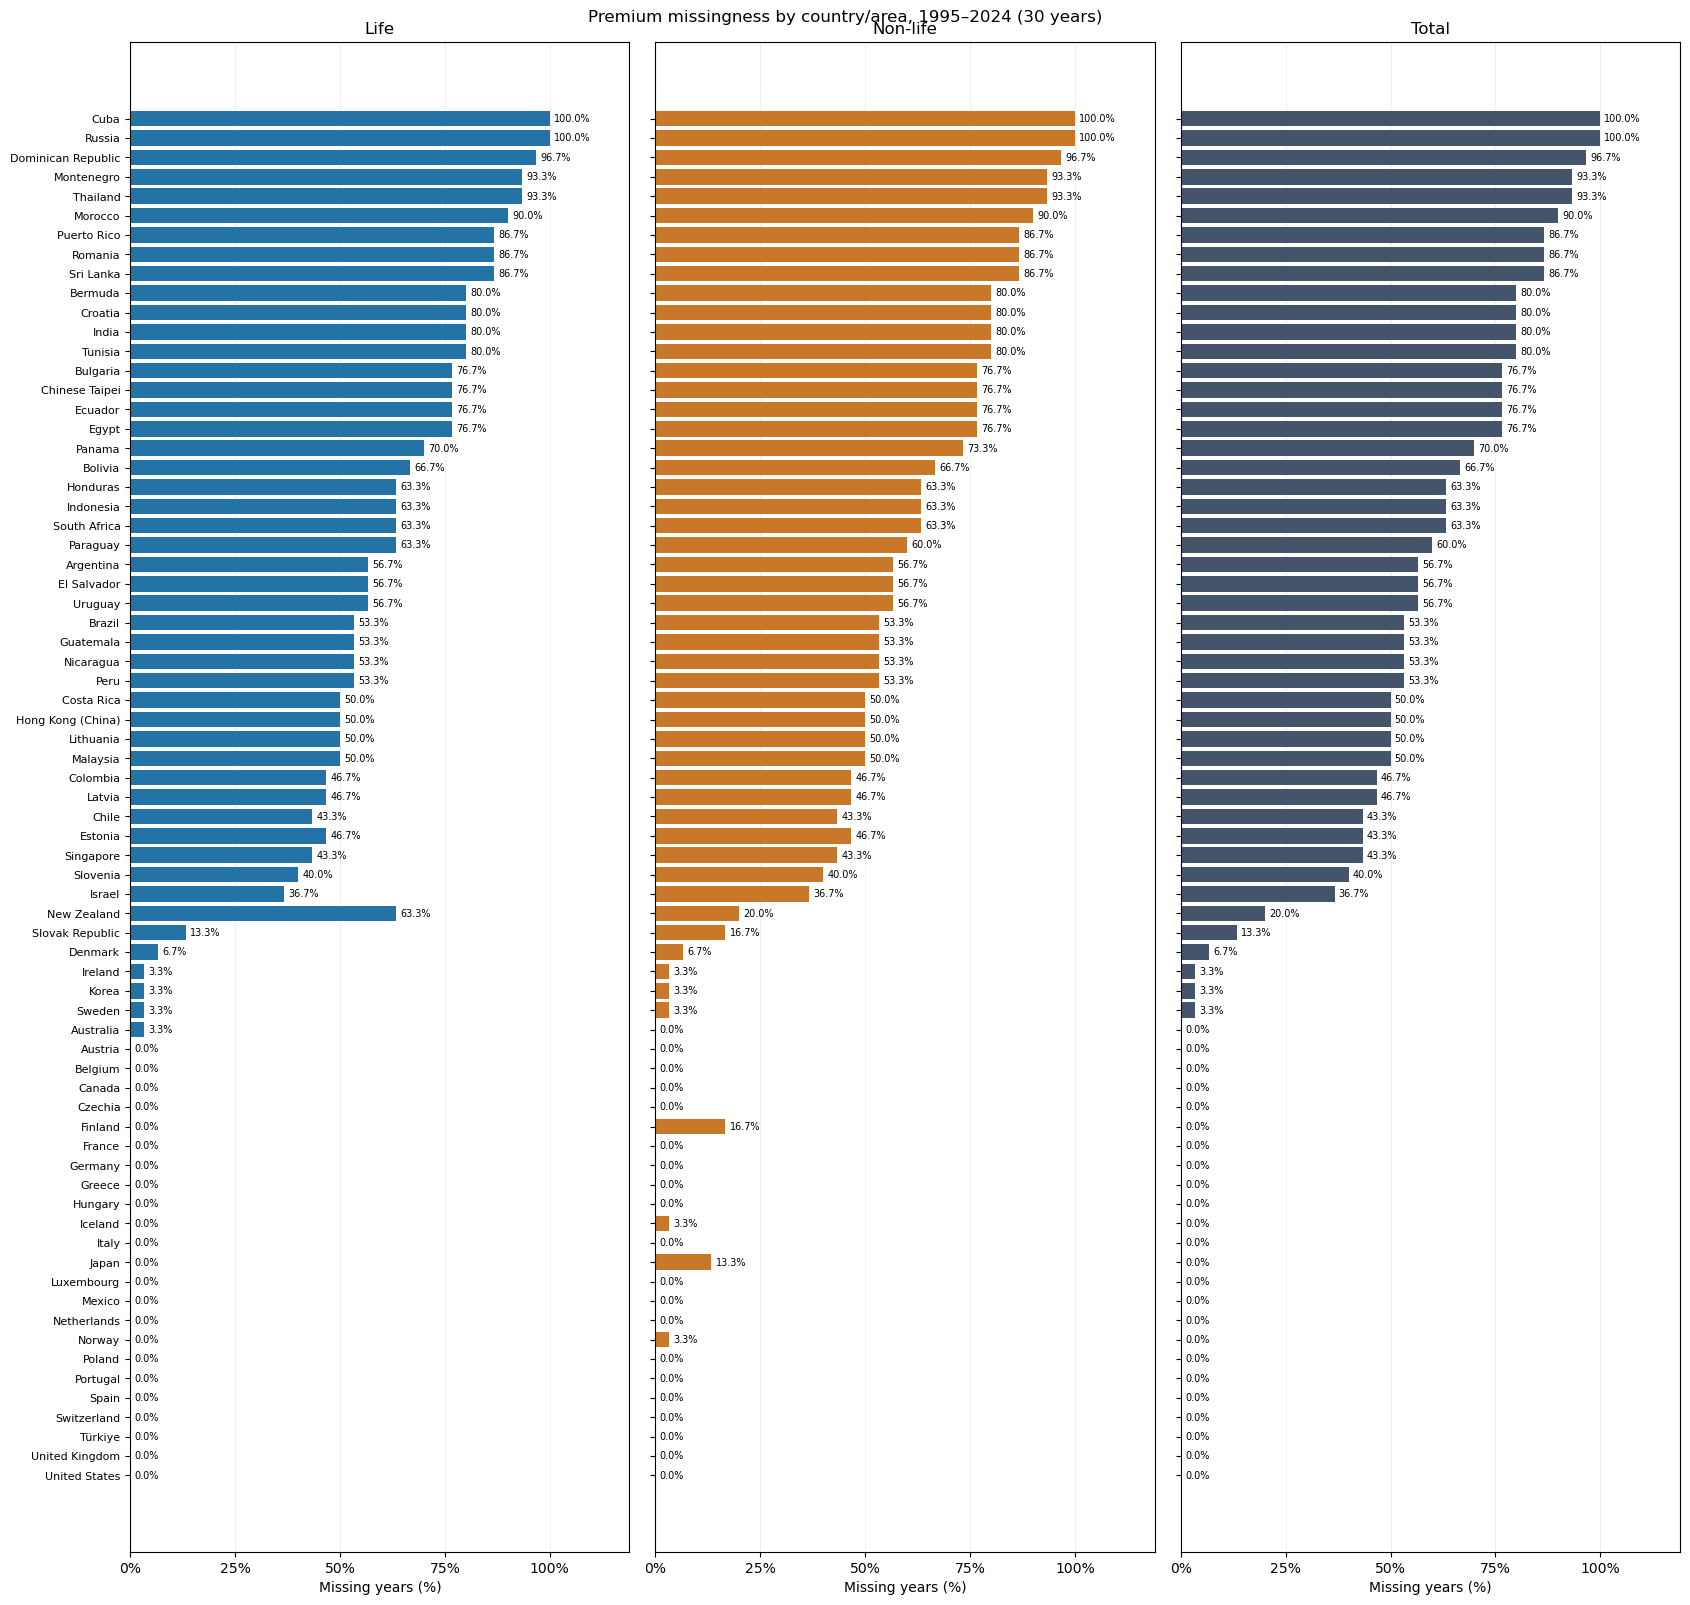

In [6]:
colors = {"Life": "#2373a6", "Non-life": "#c87828", "Total": "#44546a"}

country_missingness_rates = country_missingness_summary.pivot(index="Country", columns="Sector", values="Missing_rate_pct")

countries_sorted_by_missingness = country_missingness_rates.sort_values("Total", ascending=False, kind="stable").index

fig, axes = plt.subplots(1, 3, figsize=(17, max(7, len(country_names_by_code) * 0.23)), sharey=True)

for ax, sector_name in zip(axes, insurance_sectors):
    rates = country_missingness_rates.loc[countries_sorted_by_missingness, sector_name]
    bars = ax.barh(countries_sorted_by_missingness, rates, color=colors[sector_name])
    ax.bar_label(bars, labels=[f"{rate:.1f}%" for rate in rates], padding=3, fontsize=7)
    ax.set(title=sector_name, xlabel="Missing years (%)", xlim=(0, 119))
    ax.set_xticks(range(0, 101, 25))
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].invert_yaxis()

fig.suptitle(f"Premium missingness by country/area, {analysis_years[0]}–{analysis_years[-1]} ({len(analysis_years)} years)")
fig.tight_layout()
plt.show()
plt.close(fig)

## 7. Plot missing and partial country-years

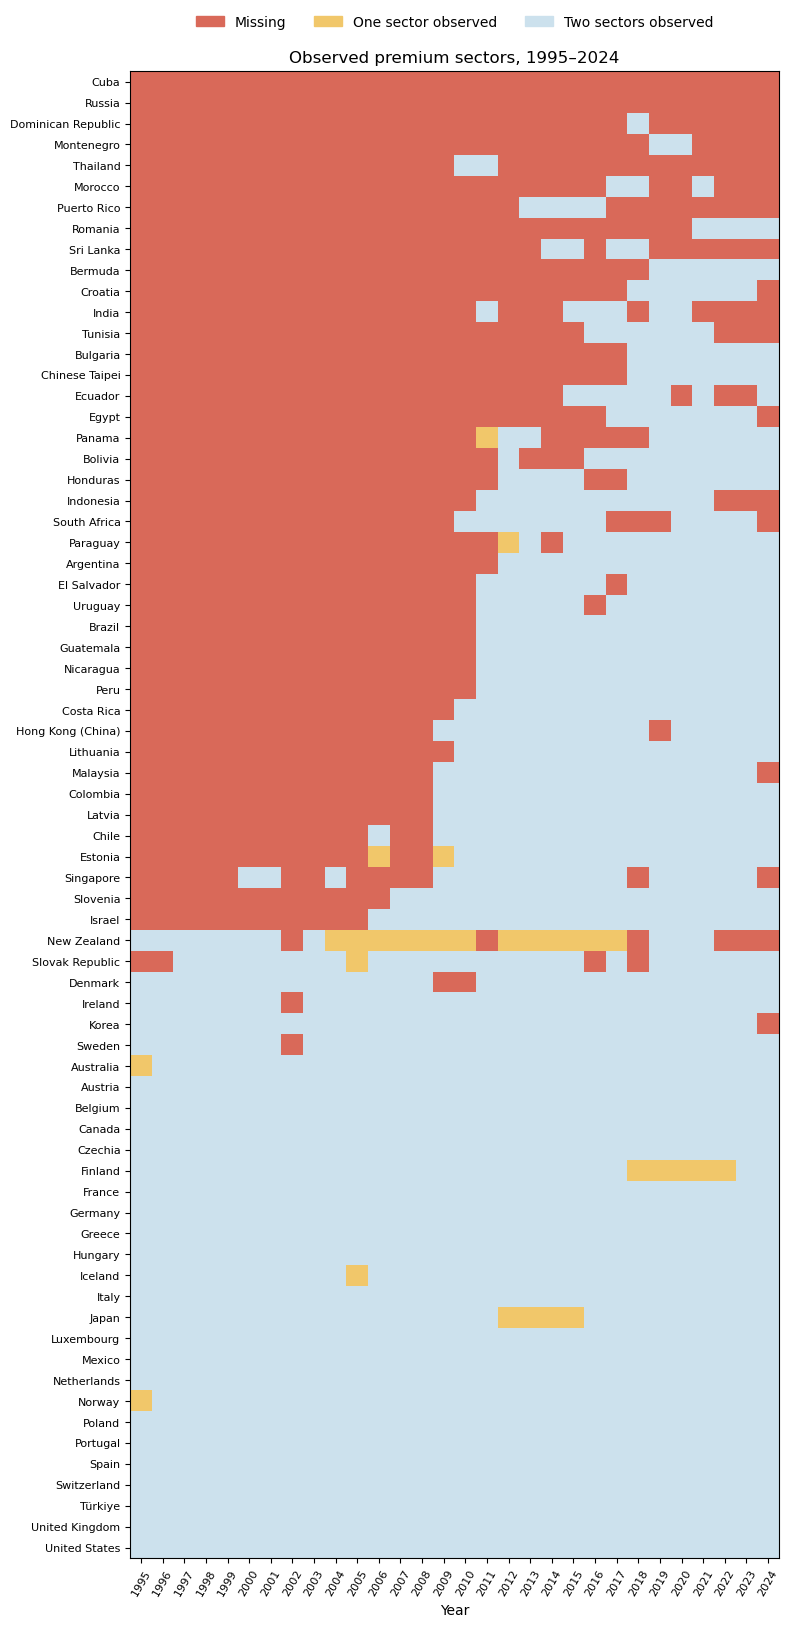

In [7]:
observed_sector_count = premium_tables_by_sector["Life"].notna().astype(int) + premium_tables_by_sector["Non-life"].notna().astype(int)
palette = ["#d96959", "#f1c76a", "#cce1ed"]

fig, ax = plt.subplots(figsize=(8, max(3, len(country_names_by_code) * 0.23)))

ax.imshow(observed_sector_count.loc[countries_sorted_by_missingness], aspect="auto", cmap=ListedColormap(palette),
          norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3), interpolation="nearest")
ax.set_xticks(range(len(analysis_years)), labels=analysis_years, rotation=60, fontsize=8)
ax.set_yticks(range(len(countries_sorted_by_missingness)), labels=countries_sorted_by_missingness, fontsize=8)
ax.set(title=f"Observed premium sectors, {analysis_years[0]}–{analysis_years[-1]}", xlabel="Year")
ax.legend(handles=[Patch(color=color, label=label) for color, label in zip(palette,
          ["Missing", "One sector observed", "Two sectors observed"])],
          loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False)

fig.tight_layout()

plt.show()
plt.close(fig)

## 8. Select countries and save the prepared inputs

In [8]:
# Select countries from combined premiums, using the full 30-year period.
total_missing_rate_by_country = premium_tables_by_sector["Total"].isna().mean(axis=1).mul(100)
selected_country_names = total_missing_rate_by_country.index[total_missing_rate_by_country.lt(maximum_missing_percent)]
selected_country_codes = country_names_by_code.index[country_names_by_code.isin(selected_country_names)]
if selected_country_codes.empty:
    raise ValueError("No countries meet the missingness threshold.")

# Preserve every insurance column and value; filter only the reference area.
selected_insurance_rows = insurance_rows_for_export.loc[insurance_rows_for_export["REF_AREA"].isin(selected_country_codes)].copy()

# Keep the World Bank metadata and the same 30 year columns.
wb_columns = ["Country Name", "Country Code", "Indicator Name", "Indicator Code"] + year_columns
worldbank_tables_for_export = {}
for filename in ["worldbank_gdp.csv", "worldbank_population_total.csv"]:
    worldbank_source_table = pd.read_csv(
        project_folder / "dataset_raw" / filename, usecols=wb_columns,
        dtype=str, keep_default_na=False,
    )
    missing_codes = set(selected_country_codes) - set(worldbank_source_table["Country Code"])
    if missing_codes:
        raise ValueError(f"{filename}: selected countries absent from the source: {sorted(missing_codes)}")
    if worldbank_source_table["Country Code"].duplicated().any():
        raise ValueError(f"{filename}: duplicate country codes. Check the indicator scope.")
    worldbank_tables_for_export["02_" + filename] = worldbank_source_table.loc[
        worldbank_source_table["Country Code"].isin(selected_country_codes), wb_columns
    ].copy()

# Save after both World Bank sources pass the country checks.
selected_insurance_rows.to_csv(data_folder / "02_selected_insurance_rows.csv", index=False, encoding="utf-8-sig")
for filename, table in worldbank_tables_for_export.items():
    table.to_csv(data_folder / filename, index=False, encoding="utf-8-sig")

print(f"Selected {len(selected_country_codes)} countries: Total missingness < {maximum_missing_percent}%.")

display(total_missing_rate_by_country.loc[selected_country_names].rename("Total missingness (%)").to_frame())
print(f"Saved insurance source rows: {len(selected_insurance_rows):,}")

Selected 30 countries: Total missingness < 30%.


,Total missingness (%)
Country,
Australia,0.000000
Austria,0.000000
Belgium,0.000000
Canada,0.000000
Czechia,0.000000
Denmark,6.666667
Finland,0.000000
France,0.000000
Germany,0.000000


Saved insurance source rows: 8,973


## 9. Save missingness tables and show the selected-country bar chart

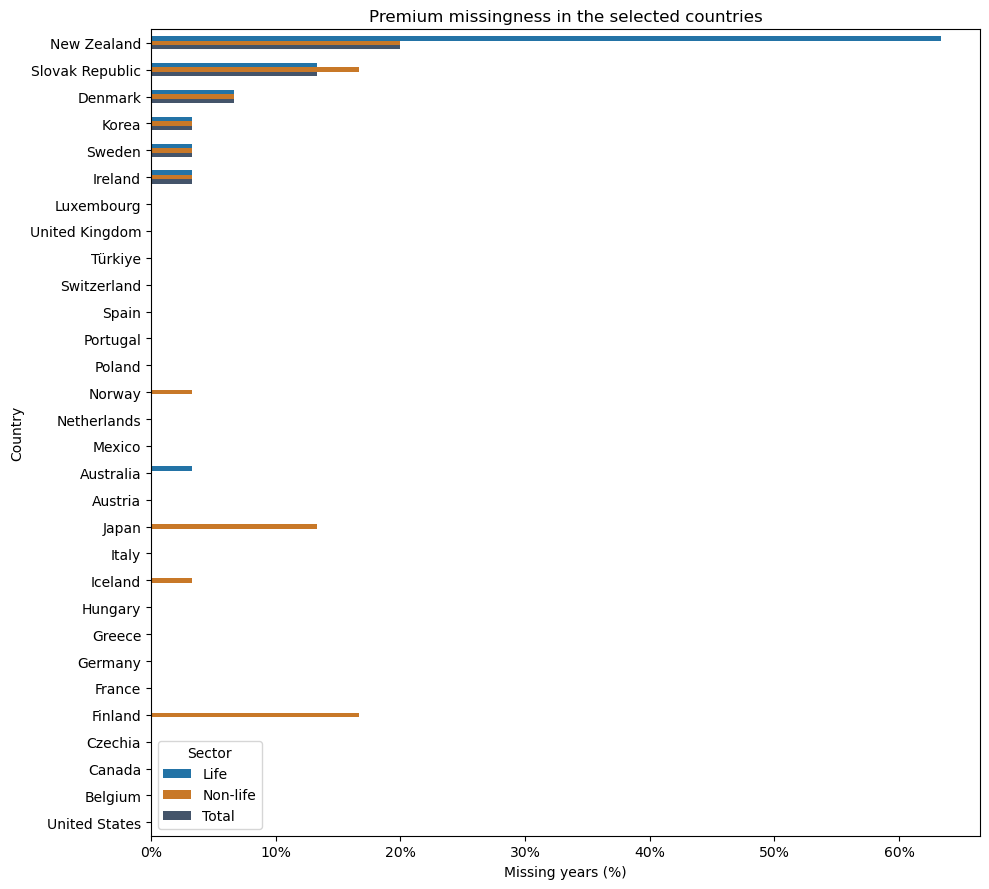

In [9]:


selected_country_table = country_names_by_code.loc[selected_country_codes].rename("Country").reset_index()
selected_country_table["Total_missing_percent"] = selected_country_table["Country"].map(total_missing_rate_by_country)
selected_country_rates = country_missingness_rates.loc[selected_country_names].sort_values("Total", ascending=False)

fig, ax = plt.subplots(figsize=(10, 9))
selected_country_rates.plot.barh(ax=ax, color=[colors[name] for name in insurance_sectors])
ax.set(title="Premium missingness in the selected countries", xlabel="Missing years (%)", ylabel="Country")
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.invert_yaxis()
fig.tight_layout()
plt.show()

plt.close(fig)